# TP — Comparaison de 13 réseaux pré-entraînés (transfert d'apprentissage + t-SNE)

**Réseaux de Neurones & Deep Learning II · ÉNSP Yaoundé · Groupe 3**

**Objectif.** Le TP précédent (`TP_VGG19_tSNE_Flipkart.ipynb`) utilisait VGG19 comme extracteur de caractéristiques.
On refait exactement la même démarche avec **tous les grands réseaux convolutifs pré-entraînés sur ImageNet disponibles dans Keras**,
sur **les mêmes 1 050 images Flipkart (7 catégories)**, pour savoir lequel donne les caractéristiques les plus utiles.

Pour chaque modèle : couches entièrement connectées retirées (`include_top=False`), moyenne globale (`pooling="avg"`),
prétraitement propre au modèle (`preprocess_input`), puis les mêmes mesures que dans le TP VGG19.

Plan : 1. données · 2. modèles comparés · 3. extraction · 4. mesures · 5. classement · 6. t-SNE de tous les modèles · 7. analyse du meilleur · 8. conclusion.

## 0. Bibliothèques et paramètres

In [1]:
import os, re, glob, ast, time, unicodedata, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
Image.MAX_IMAGE_PIXELS = None   # une image Flipkart dépasse 89 Mpx : jeu de données de confiance

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import applications as A

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score, confusion_matrix
from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, cross_val_predict, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

print("TensorFlow", tf.__version__, "·", "GPU" if tf.config.list_physical_devices("GPU") else "CPU seulement")

TensorFlow 2.21.0 · CPU seulement


In [2]:
# ---------------------------------------------------------------
# À ADAPTER : chemin du dossier Flipkart sur votre ordinateur
# ---------------------------------------------------------------
DATA_DIR = r"C:\Users\Lenovo\Documents\mes cours\Réseaux de Neurones  Deep Learning II\Dataset+projet+prétraitement+textes+images\Flipkart"

def resoudre_chemin(chemin):
    """Retrouve un dossier même si ses accents sont encodés autrement sur le disque.

    Un dossier extrait d'un zip peut écrire « é » en deux caractères (e + accent combinant) :
    à l'écran c'est identique, mais Windows y voit un autre nom et le chemin « n'existe pas ».
    On compare donc les noms après normalisation Unicode (NFC), dossier par dossier.
    """
    if os.path.isdir(chemin):
        return chemin
    nfc = lambda s: unicodedata.normalize("NFC", s)
    lecteur, reste = os.path.splitdrive(os.path.abspath(chemin))
    courant = lecteur + os.sep
    for partie in [p for p in reste.split(os.sep) if p]:
        candidat = os.path.join(courant, partie)
        if not os.path.isdir(candidat):
            trouves = [n for n in os.listdir(courant) if nfc(n) == nfc(partie)]
            if not trouves:
                return chemin          # vraiment introuvable : on laisse l'erreur se produire plus loin
            candidat = os.path.join(courant, trouves[0])
        courant = candidat
    return courant

# Si le notebook est rangé à côté du dossier Flipkart, on l'utilise directement
if os.path.isdir("Flipkart"):
    DATA_DIR = os.path.abspath("Flipkart")
DATA_DIR = resoudre_chemin(DATA_DIR)
print("Dossier des données :", DATA_DIR, "->", "trouvé" if os.path.isdir(DATA_DIR) else "INTROUVABLE")

WEIGHTS    = "imagenet"
IMG_SIZE   = 224          # même taille pour tous les modèles : comparaison équitable et plus rapide
BATCH_SIZE = 32
SEED       = 42
OUT_DIR    = "resultats_comparaison"   # figures et caractéristiques sauvegardées ici
os.makedirs(OUT_DIR, exist_ok=True)
np.random.seed(SEED)
tf.random.set_seed(SEED)

def sauver_figure(nom, **options):
    """Enregistre la figure courante dans OUT_DIR.
    Si le fichier est ouvert dans une visionneuse (ex. l'application Photos), Windows refuse
    de l'écraser (OSError, Errno 22 ou 13) : on enregistre alors sous un autre nom au lieu de planter."""
    chemin = os.path.join(OUT_DIR, nom)
    try:
        plt.savefig(chemin, **options)
    except OSError:
        base, ext = os.path.splitext(chemin)
        chemin = f"{base}_{time.strftime('%H%M%S')}{ext}"
        plt.savefig(chemin, **options)
        print(f"Fichier d'origine verrouillé (ouvert ailleurs ?) : figure enregistrée sous {chemin}")

Dossier des données : c:\Users\Lenovo\Documents\mes cours\Réseaux de Neurones  Deep Learning II\Dataset+projet+prétraitement+textes+images\Flipkart -> trouvé


## 1. Chargement des données

Même fonction de chargement que dans le TP VGG19 : mêmes images, mêmes catégories (premier niveau de `product_category_tree`).

In [3]:
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")
COL_IMAGE = None       # ex. "image"                  (None = détection automatique)
COL_CATEGORIE = None   # ex. "product_category_tree"  (None = détection automatique)

def premier_niveau(arbre):
    # '["A >> B >> C"]'  ->  'A'   ;   'Watches'  ->  'Watches'
    try:
        arbre = ast.literal_eval(arbre)[0]
    except Exception:
        arbre = str(arbre).strip('[]"\' ')
    return arbre.split(">>")[0].strip()

def lire_tableau(fichier):
    if fichier.lower().endswith(".csv"):
        return pd.read_csv(fichier)
    return pd.read_excel(fichier)   # .xlsx : openpyxl ; .xls : xlrd

def trouver_colonnes(tab, images):
    col_img = COL_IMAGE
    if col_img is None:
        scores = {c: tab[c].fillna("").astype(str).str.strip().map(lambda v: os.path.basename(v) in images).mean() for c in tab.columns}
        col_img = max(scores, key=scores.get)
        if scores[col_img] == 0:
            return None, None
    col_cat = COL_CATEGORIE
    if col_cat is None:
        noms = {c.lower(): c for c in tab.columns}
        col_cat = noms.get("product_category_tree") or next(
            (c for c in tab.columns if re.search(r"cat[eé]g|label|class|target|famille|type", str(c), re.I) and c != col_img), None)
    return col_img, col_cat

def charger_flipkart(racine):
    if not os.path.isdir(racine):
        raise FileNotFoundError(f"Dossier introuvable : {racine}")
    # Toutes les images présentes, indexées par nom de fichier
    images = {}
    for chemin in glob.glob(os.path.join(racine, "**", "*"), recursive=True):
        if chemin.lower().endswith(IMG_EXT):
            images.setdefault(os.path.basename(chemin), chemin)
    print(f"{len(images)} fichiers image trouvés dans le dossier.")

    # Cas 1 : un fichier Excel ou CSV qui associe chaque image à sa catégorie
    tableaux = [f for ext in ("xlsx", "xls", "csv") for f in glob.glob(os.path.join(racine, "**", f"*.{ext}"), recursive=True)
                if not os.path.basename(f).startswith("~$")]   # ignore les fichiers temporaires d'Excel ouvert
    for fichier in tableaux:
        try:
            tab = lire_tableau(fichier)
        except Exception as e:
            print(f"Lecture impossible de {os.path.basename(fichier)} : {e}")
            continue
        col_img, col_cat = trouver_colonnes(tab, images)
        if col_img is None or col_cat is None:
            continue
        df = pd.DataFrame({"image": tab[col_img].fillna("").astype(str).str.strip().map(os.path.basename),
                           "categorie": tab[col_cat].apply(premier_niveau)})
        if "product_name" in tab:
            df["product_name"] = tab["product_name"]
        df["chemin"] = df["image"].map(images)
        manquantes = df["chemin"].isna().sum()
        if manquantes:
            print(f"Attention : {manquantes} images citées dans le fichier sont absentes du dossier.")
        print(f"Fichier utilisé : {os.path.basename(fichier)} · colonne image = '{col_img}' · colonne catégorie = '{col_cat}'")
        return df.dropna(subset=["chemin"]).reset_index(drop=True)

    # Cas 2 : un sous-dossier par catégorie
    lignes = [{"image": n, "chemin": c, "categorie": os.path.basename(os.path.dirname(c))} for n, c in images.items()]
    if not lignes:
        raise FileNotFoundError("Aucune image trouvée dans ce dossier.")
    print("Pas de fichier Excel/CSV exploitable : la catégorie est lue dans le nom du sous-dossier.")
    return pd.DataFrame(lignes)

df = charger_flipkart(DATA_DIR)
CATEGORIES = sorted(df["categorie"].unique())
print(f"{len(df)} images, {len(CATEGORIES)} catégories")
df["categorie"].value_counts().to_frame("nombre d'images")

1050 fichiers image trouvés dans le dossier.
Fichier utilisé : flipkart_com-ecommerce_sample_1050.csv · colonne image = 'image' · colonne catégorie = 'product_category_tree'
1050 images, 7 catégories


,nombre d'images
categorie,
Home Furnishing,150
Baby Care,150
Watches,150
Home Decor & Festive Needs,150
Kitchen & Dining,150
Beauty and Personal Care,150
Computers,150


Pour aller vite, les 1 050 images sont lues et redimensionnées en $224\times224$ **une seule fois**, puis gardées en mémoire (≈ 160 Mo en entiers 8 bits).
Tous les modèles reçoivent donc exactement les mêmes pixels.

In [4]:
def lire_image(chemin):
    img = keras.utils.load_img(chemin, target_size=(IMG_SIZE, IMG_SIZE), color_mode="rgb")
    return np.asarray(img, dtype=np.uint8)

debut = time.time()
IMAGES = np.stack([lire_image(c) for c in df["chemin"]])
y = df["categorie"].astype(str).to_numpy()
print(f"Images en mémoire : {IMAGES.shape} · {IMAGES.nbytes / 1e6:.0f} Mo · lues en {time.time() - debut:.0f} s")

Images en mémoire : (1050, 224, 224, 3) · 158 Mo · lues en 12 s


## 2. Les modèles comparés

On prend un représentant de chaque grande famille d'architectures de `keras.applications` (plus quelques variantes de taille),
de la plus ancienne à la plus récente :

| Famille | Idée principale |
|---|---|
| **VGG16 / VGG19** (2014) | empilement simple de convolutions $3\times3$ |
| **InceptionV3** (2015), **Xception** (2016), **InceptionResNetV2** (2016) | convolutions de plusieurs tailles en parallèle ; convolutions séparables |
| **ResNet50 / ResNet101 / ResNet50V2** (2015-16) | connexions résiduelles (raccourcis) qui permettent des réseaux très profonds |
| **DenseNet121** (2017) | chaque couche reçoit les sorties de toutes les précédentes |
| **MobileNetV2** (2018) | réseau léger pour téléphone |
| **EfficientNetB0** (2019), **EfficientNetV2B0** (2021) | largeur, profondeur et résolution réglées ensemble |
| **ConvNeXtTiny** (2022) | CNN « modernisé » avec les recettes des Transformers |

Chaque modèle a **sa propre fonction `preprocess_input`** (normalisation attendue par ses poids) : l'utiliser est indispensable.
Pour EfficientNet et ConvNeXt, la normalisation est déjà intégrée au modèle et `preprocess_input` ne fait rien.

In [5]:
MODELES = {
    "VGG16":             (A.VGG16,             A.vgg16.preprocess_input),
    "VGG19":             (A.VGG19,             A.vgg19.preprocess_input),
    "ResNet50":          (A.ResNet50,          A.resnet.preprocess_input),
    "ResNet101":         (A.ResNet101,         A.resnet.preprocess_input),
    "ResNet50V2":        (A.ResNet50V2,        A.resnet_v2.preprocess_input),
    "InceptionV3":       (A.InceptionV3,       A.inception_v3.preprocess_input),
    "Xception":          (A.Xception,          A.xception.preprocess_input),
    "InceptionResNetV2": (A.InceptionResNetV2, A.inception_resnet_v2.preprocess_input),
    "DenseNet121":       (A.DenseNet121,       A.densenet.preprocess_input),
    "MobileNetV2":       (A.MobileNetV2,       A.mobilenet_v2.preprocess_input),
    "EfficientNetB0":    (A.EfficientNetB0,    A.efficientnet.preprocess_input),
    "EfficientNetV2B0":  (A.EfficientNetV2B0,  A.efficientnet_v2.preprocess_input),
    "ConvNeXtTiny":      (A.ConvNeXtTiny,      A.convnext.preprocess_input),
}
print(len(MODELES), "modèles :", ", ".join(MODELES))

13 modèles : VGG16, VGG19, ResNet50, ResNet101, ResNet50V2, InceptionV3, Xception, InceptionResNetV2, DenseNet121, MobileNetV2, EfficientNetB0, EfficientNetV2B0, ConvNeXtTiny


## 3. Extraction des caractéristiques

Pour chaque modèle : chargement sans couches FC, passage des 1 050 images par lots, puis sauvegarde dans `resultats_comparaison/`.
Au deuxième lancement, rien n'est recalculé. On note aussi le **nombre de paramètres**, la **taille du vecteur** et le **temps d'extraction**
(sur CPU), utiles pour départager deux modèles proches.

In [6]:
CARAC, INFOS = {}, {}
for nom, (constructeur, pretraitement) in MODELES.items():
    cache = os.path.join(OUT_DIR, f"carac_{nom}_{len(df)}.npz")
    if os.path.exists(cache):
        d = np.load(cache)
        CARAC[nom] = d["X"]
        INFOS[nom] = {"paramètres (M)": float(d["params"]) / 1e6, "temps (s)": float(d["temps"])}
        print(f"{nom:<18} rechargé depuis le cache · {CARAC[nom].shape[1]} dim.")
        continue
    modele = constructeur(weights=WEIGHTS, include_top=False, pooling="avg", input_shape=(IMG_SIZE, IMG_SIZE, 3))
    modele.trainable = False
    debut, morceaux = time.time(), []
    for i in range(0, len(IMAGES), BATCH_SIZE):
        lot = pretraitement(IMAGES[i:i + BATCH_SIZE].astype("float32"))   # copie : preprocess_input peut modifier en place
        morceaux.append(modele(lot, training=False).numpy())
    temps = time.time() - debut
    X = np.vstack(morceaux).astype("float32")
    np.savez_compressed(cache, X=X, params=modele.count_params(), temps=temps)
    CARAC[nom] = X
    INFOS[nom] = {"paramètres (M)": modele.count_params() / 1e6, "temps (s)": temps}
    print(f"{nom:<18} {X.shape[1]:>5} dim. · {modele.count_params() / 1e6:5.1f} M paramètres · {temps:5.0f} s")
    del modele; keras.backend.clear_session(); gc.collect()

VGG16              rechargé depuis le cache · 512 dim.
VGG19              rechargé depuis le cache · 512 dim.
ResNet50           rechargé depuis le cache · 2048 dim.
A local file was found, but it seems to be incomplete or outdated because the auto file hash does not match the original value of 88cf7a10940856eca736dc7b7e228a21 so we will re-download the data.
171446536/171446536 ━━━━━━━━━━━━━━━━━━━━ 83s 0us/step
ResNet101           2048 dim. ·  42.7 M paramètres ·   160 s

94668760/94668760 ━━━━━━━━━━━━━━━━━━━━ 45s 0us/step
ResNet50V2          2048 dim. ·  23.6 M paramètres ·    68 s
87910968/87910968 ━━━━━━━━━━━━━━━━━━━━ 43s 0us/step
InceptionV3         2048 dim. ·  21.8 M paramètres ·    51 s
83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 43s 1us/step
Xception            2048 dim. ·  20.9 M paramètres ·    80 s
219055592/219055592 ━━━━━━━━━━━━━━━━━━━━ 107s 0us/step
InceptionResNetV2   1536 dim. ·  54.3 M paramètres ·   134 s
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 17s 1us/step
DenseNet121    

## 4. Mesures pour chaque modèle

Mêmes mesures que dans le TP VGG19, plus un second classifieur :

- **Précision régression logistique** sur toutes les caractéristiques, validation croisée stratifiée à 5 plis (mêmes plis pour tous) : *le critère principal*,
  il répond directement à « ce modèle permet-il de classer ces images ? » ;
- **Précision k plus proches voisins** (k = 5, distance cosinus) : un classifieur sans entraînement, qui mesure si les images d'une même catégorie sont *voisines* dans l'espace des caractéristiques ;
- sur le **graphe t-SNE 2D** (ACP à 50 composantes puis perplexité 30, comme dans le TP VGG19) : **pureté du voisinage** (10 voisins), **ARI** de K-means et **silhouette**.

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def evaluer(X):
    lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.1))
    knn = KNeighborsClassifier(n_neighbors=5, metric="cosine")
    acc_lr = cross_val_score(lr, X, y, cv=cv, scoring="accuracy", n_jobs=-1)
    acc_knn = cross_val_score(knn, X, y, cv=cv, scoring="accuracy")
    Xp = PCA(n_components=min(50, X.shape[1]), random_state=SEED).fit_transform(StandardScaler().fit_transform(X))
    P = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED).fit_transform(Xp)
    _, vois = NearestNeighbors(n_neighbors=11).fit(P).kneighbors(P)
    grp = KMeans(n_clusters=len(CATEGORIES), n_init=10, random_state=SEED).fit_predict(P)
    return P, {
        "précision LogReg": acc_lr.mean(), "écart-type LogReg": acc_lr.std(),
        "précision k-NN": acc_knn.mean(),
        "pureté t-SNE": (y[vois[:, 1:]] == y[:, None]).mean(),
        "ARI t-SNE": adjusted_rand_score(y, grp),
        "silhouette t-SNE": silhouette_score(P, y),
    }

PROJ, RES = {}, {}
debut = time.time()
for nom, X in CARAC.items():
    PROJ[nom], RES[nom] = evaluer(X)
    RES[nom].update({"dimension": X.shape[1], **INFOS[nom]})
    print(f"{nom:<18} LogReg {RES[nom]['précision LogReg']:.1%} · k-NN {RES[nom]['précision k-NN']:.1%} · pureté t-SNE {RES[nom]['pureté t-SNE']:.1%}")
print(f"Évaluation terminée en {time.time() - debut:.0f} s")

VGG16              LogReg 82.2% · k-NN 81.6% · pureté t-SNE 73.8%
VGG19              LogReg 83.1% · k-NN 81.3% · pureté t-SNE 73.8%
ResNet50           LogReg 85.4% · k-NN 84.3% · pureté t-SNE 76.4%
ResNet101          LogReg 85.0% · k-NN 83.8% · pureté t-SNE 76.5%
ResNet50V2         LogReg 84.8% · k-NN 83.9% · pureté t-SNE 76.3%
InceptionV3        LogReg 84.3% · k-NN 83.3% · pureté t-SNE 77.0%
Xception           LogReg 84.6% · k-NN 82.6% · pureté t-SNE 79.0%
InceptionResNetV2  LogReg 85.3% · k-NN 85.7% · pureté t-SNE 77.8%
DenseNet121        LogReg 85.0% · k-NN 85.0% · pureté t-SNE 78.7%
MobileNetV2        LogReg 83.1% · k-NN 83.2% · pureté t-SNE 76.8%
EfficientNetB0     LogReg 86.2% · k-NN 84.2% · pureté t-SNE 78.6%
EfficientNetV2B0   LogReg 86.8% · k-NN 85.8% · pureté t-SNE 81.6%
ConvNeXtTiny       LogReg 88.5% · k-NN 83.2% · pureté t-SNE 80.8%
Évaluation terminée en 84 s


## 5. Classement

Les modèles sont triés par précision de la régression logistique. La dernière colonne donne le **rang moyen** sur les cinq mesures de qualité :
un modèle bien classé partout est plus convaincant qu'un modèle premier sur une seule mesure.

In [8]:
res = pd.DataFrame(RES).T
qualite = ["précision LogReg", "précision k-NN", "pureté t-SNE", "ARI t-SNE", "silhouette t-SNE"]
res["rang moyen"] = res[qualite].rank(ascending=False).mean(axis=1)
res = res.sort_values("précision LogReg", ascending=False)
res["dimension"] = res["dimension"].astype(int)
res.to_csv(os.path.join(OUT_DIR, "classement_modeles.csv"), encoding="utf-8-sig")

MEILLEUR = res.index[0]
print(f"Meilleur modèle (régression logistique) : {MEILLEUR} — {res.loc[MEILLEUR, 'précision LogReg']:.1%}")
print(f"Meilleur rang moyen                     : {res['rang moyen'].idxmin()}")
print(f"VGG19 (TP précédent)                    : {res.loc['VGG19', 'précision LogReg']:.1%}, rang {list(res.index).index('VGG19') + 1}/{len(res)}")
res.style.format({"précision LogReg": "{:.1%}", "écart-type LogReg": "{:.1%}", "précision k-NN": "{:.1%}",
                  "pureté t-SNE": "{:.1%}", "ARI t-SNE": "{:.3f}", "silhouette t-SNE": "{:.3f}",
                  "paramètres (M)": "{:.1f}", "temps (s)": "{:.0f}", "rang moyen": "{:.1f}"}) \
         .background_gradient(cmap="Greens", subset=qualite)

Meilleur modèle (régression logistique) : ConvNeXtTiny — 88.5%
Meilleur rang moyen                     : EfficientNetV2B0
VGG19 (TP précédent)                    : 83.1%, rang 11/13


,précision LogReg,écart-type LogReg,précision k-NN,pureté t-SNE,ARI t-SNE,silhouette t-SNE,dimension,paramètres (M),temps (s),rang moyen
ConvNeXtTiny,88.5%,1.6%,83.2%,80.8%,0.532,0.287,768,27.8,401,4.4
EfficientNetV2B0,86.8%,1.2%,85.8%,81.6%,0.549,0.285,1280,5.9,38,2.4
EfficientNetB0,86.2%,1.0%,84.2%,78.6%,0.576,0.295,1280,4.0,43,3.4
ResNet50,85.4%,1.7%,84.3%,76.4%,0.524,0.200,2048,23.6,131,7.4
InceptionResNetV2,85.3%,1.5%,85.7%,77.8%,0.530,0.309,1536,54.3,134,4.4
DenseNet121,85.0%,1.7%,85.0%,78.7%,0.544,0.257,1024,7.0,83,4.9
ResNet101,85.0%,0.4%,83.8%,76.5%,0.507,0.200,2048,42.7,160,8.7
ResNet50V2,84.8%,0.8%,83.9%,76.3%,0.537,0.229,2048,23.6,68,7.8
Xception,84.6%,2.1%,82.6%,79.0%,0.533,0.274,2048,20.9,80,7.0
InceptionV3,84.3%,2.6%,83.3%,77.0%,0.576,0.286,2048,21.8,51,6.0


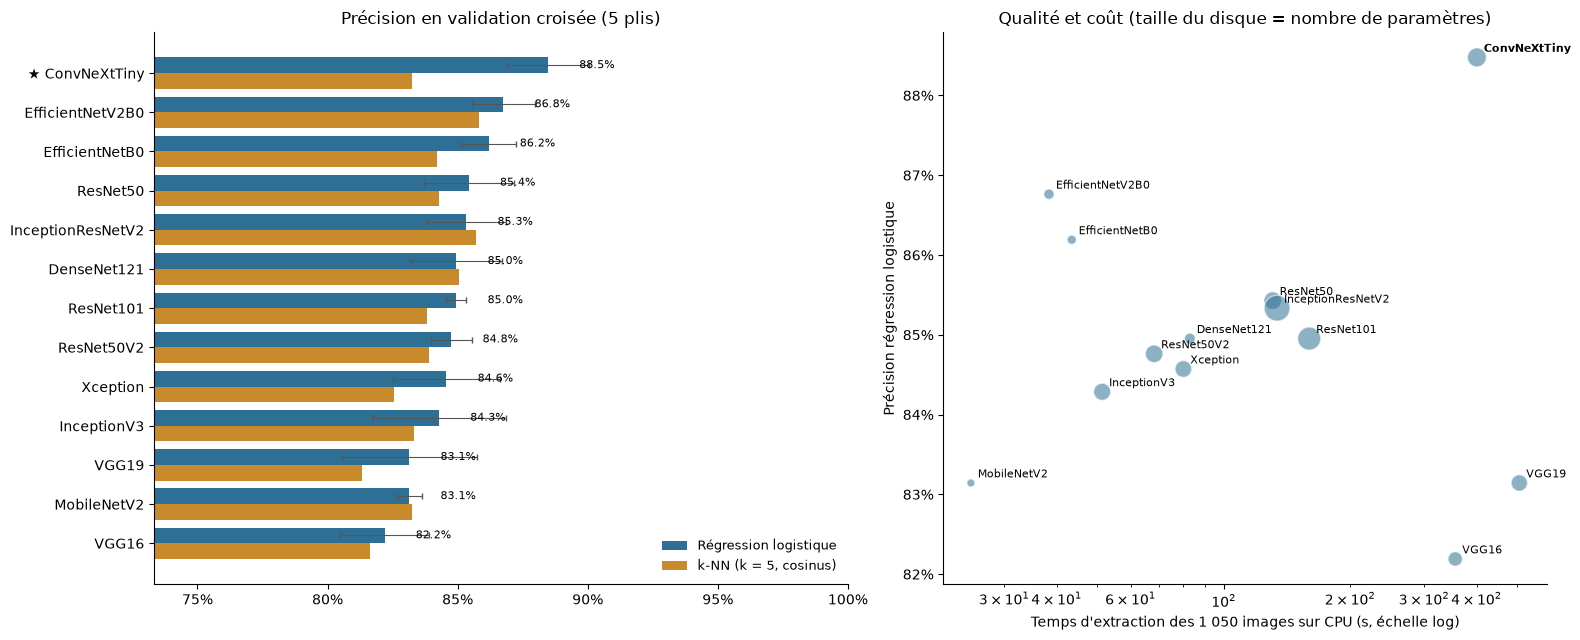

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={"width_ratios": [1.15, 1]})

# Gauche : précision des deux classifieurs, triée
ordre = res.index[::-1]
pos = np.arange(len(ordre))
ax1.barh(pos + 0.2, res.loc[ordre, "précision LogReg"], height=0.4, color="#2E6F95", label="Régression logistique",
         xerr=res.loc[ordre, "écart-type LogReg"], error_kw=dict(ecolor="#555", lw=0.8, capsize=2))
ax1.barh(pos - 0.2, res.loc[ordre, "précision k-NN"], height=0.4, color="#C98A2B", label="k-NN (k = 5, cosinus)")
for p, nom in zip(pos, ordre):
    ax1.text(res.loc[nom, "précision LogReg"] + 0.012, p + 0.2, f"{res.loc[nom, 'précision LogReg']:.1%}", va="center", fontsize=8)
ax1.set_yticks(pos, [f"★ {n}" if n == MEILLEUR else n for n in ordre])
lo = min(res["précision k-NN"].min(), res["précision LogReg"].min())
ax1.set_xlim(max(0, lo - 0.08), 1.0)
ax1.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax1.set_title("Précision en validation croisée (5 plis)", fontsize=12)
ax1.legend(loc="lower right", frameon=False, fontsize=9)
ax1.spines[["top", "right"]].set_visible(False)

# Droite : précision vs coût (temps d'extraction), taille = nombre de paramètres
ax2.scatter(res["temps (s)"], res["précision LogReg"], s=res["paramètres (M)"] * 6 + 20, color="#2E6F95", alpha=0.55, edgecolors="white")
for nom, r in res.iterrows():
    ax2.annotate(nom, (r["temps (s)"], r["précision LogReg"]), xytext=(5, 4), textcoords="offset points",
                 fontsize=8, weight="bold" if nom == MEILLEUR else "normal")
ax2.set_xscale("log")
ax2.set_xlabel("Temps d'extraction des 1 050 images sur CPU (s, échelle log)")
ax2.set_ylabel("Précision régression logistique")
ax2.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax2.set_title("Qualité et coût (taille du disque = nombre de paramètres)", fontsize=12)
ax2.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
sauver_figure("comparaison_precision.png", dpi=170, bbox_inches="tight")
plt.show()

## 6. Le t-SNE de chaque modèle

Mêmes couleurs que dans le TP VGG19. Les graphes sont rangés du meilleur au moins bon (précision de la régression logistique) ;
le titre rappelle la pureté du voisinage sur le graphe.

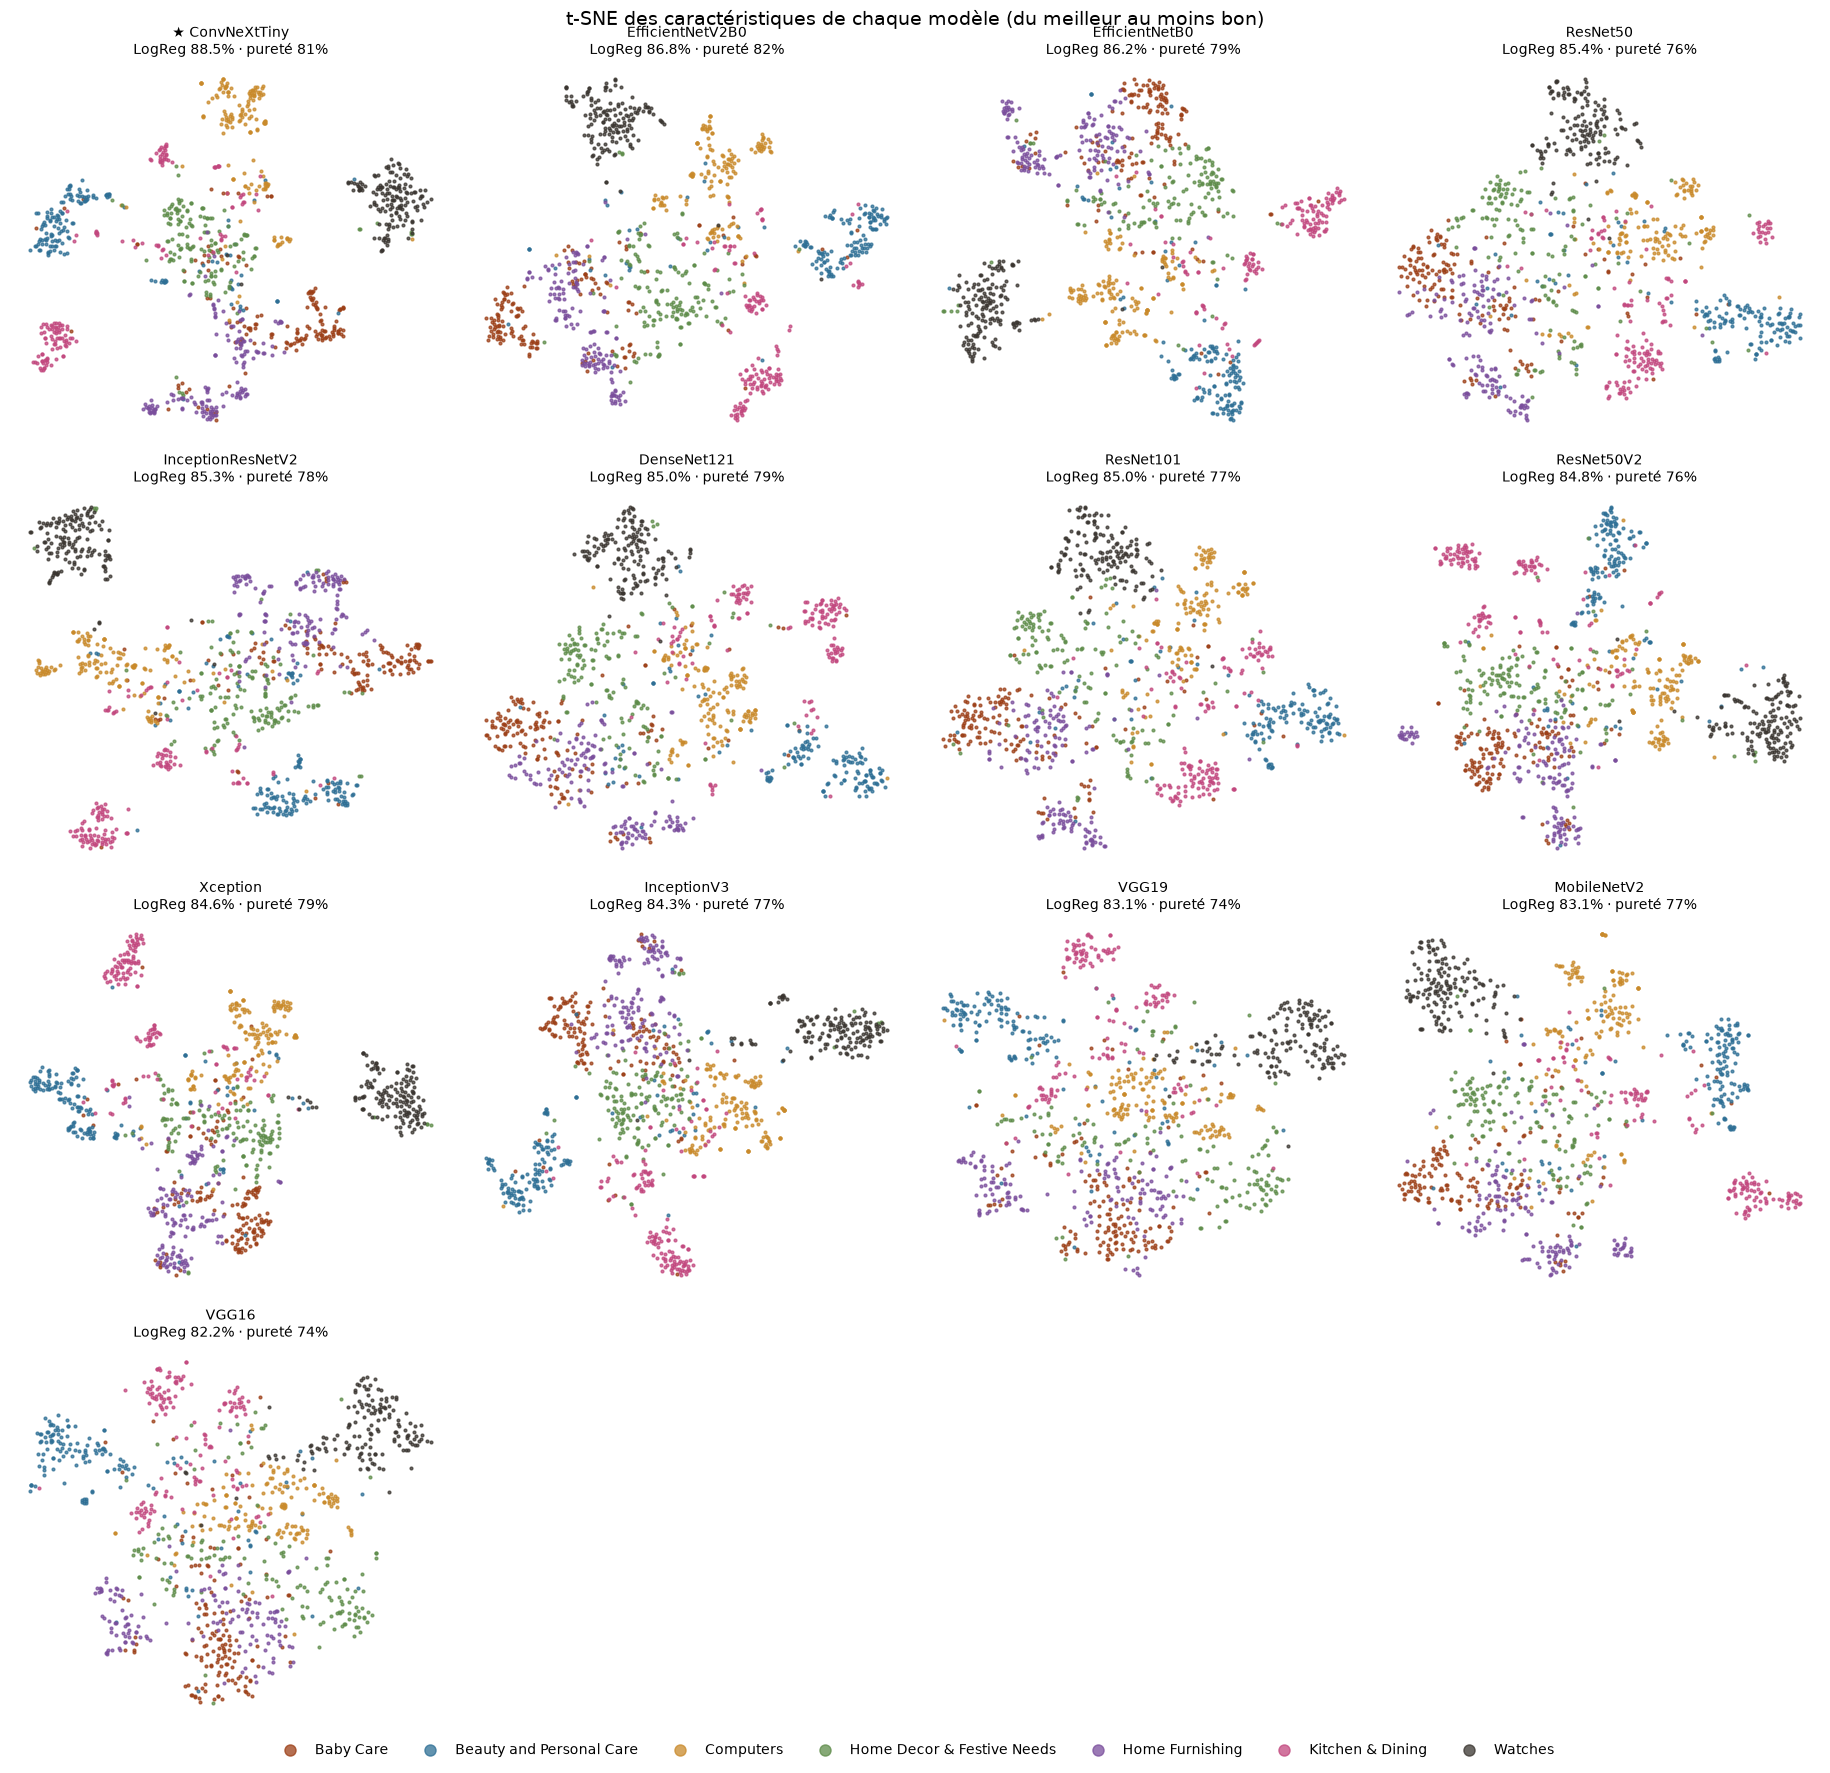

In [10]:
PALETTE = ["#9C3F17", "#2E6F95", "#C98A2B", "#5E8C4A", "#7A4E9C", "#C2477E", "#3A3530", "#3C9D9B", "#B5B23C", "#8C6D4F"]
couleurs = {c: PALETTE[i % len(PALETTE)] for i, c in enumerate(CATEGORIES)}

n_col = 4
n_lig = int(np.ceil(len(res) / n_col))
fig, axes = plt.subplots(n_lig, n_col, figsize=(4.6 * n_col, 4.4 * n_lig))
axes = axes.ravel()
for ax in axes:
    ax.axis("off")
for ax, nom in zip(axes, res.index):
    P = PROJ[nom]
    for cat in CATEGORIES:
        m = y == cat
        ax.scatter(P[m, 0], P[m, 1], s=4, alpha=0.75, color=couleurs[cat], label=cat)
    ax.set_title(f"{'★ ' if nom == MEILLEUR else ''}{nom}\nLogReg {res.loc[nom, 'précision LogReg']:.1%} · pureté {res.loc[nom, 'pureté t-SNE']:.0%}", fontsize=10)
poignees, noms = axes[0].get_legend_handles_labels()
fig.legend(poignees, noms, loc="lower center", ncol=len(CATEGORIES), frameon=False, fontsize=10, markerscale=4, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("t-SNE des caractéristiques de chaque modèle (du meilleur au moins bon)", fontsize=14)
plt.tight_layout()
sauver_figure("tsne_tous_modeles.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Le meilleur modèle face à VGG19

On compare, catégorie par catégorie, la précision (rappel) obtenue avec les caractéristiques du meilleur modèle et avec celles de VGG19,
puis on affiche la matrice de confusion du meilleur modèle. On voit ainsi **où** le gain se fait.

,VGG19,ConvNeXtTiny,gain (points)
Beauty and Personal Care,79.3%,87.3%,+8.0
Home Decor & Festive Needs,79.3%,87.3%,+8.0
Home Furnishing,80.0%,87.3%,+7.3
Computers,88.7%,94.7%,+6.0
Watches,95.3%,99.3%,+4.0
Baby Care,72.0%,74.7%,+2.7
Kitchen & Dining,87.3%,88.7%,+1.3


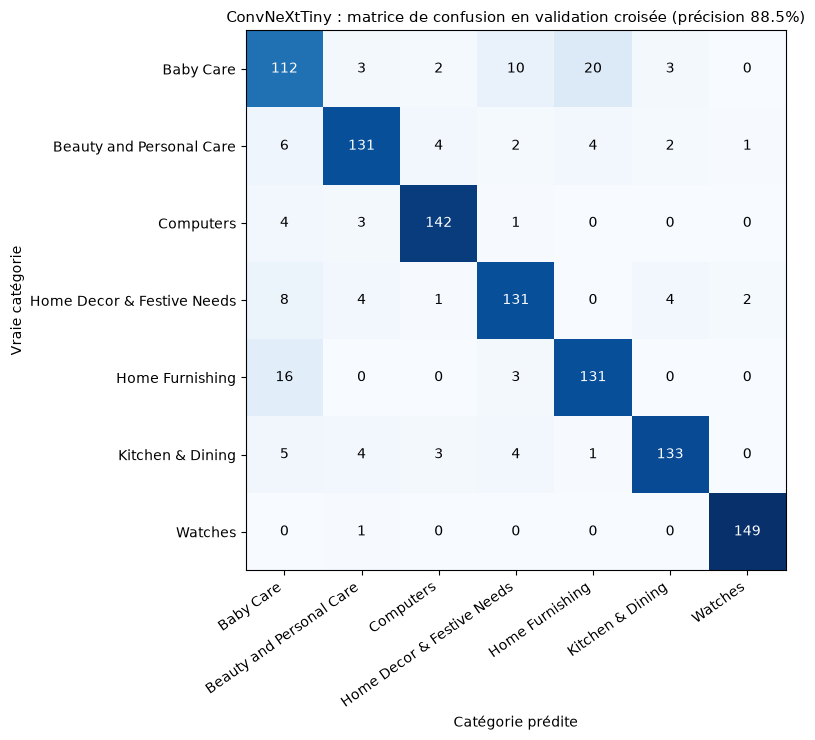

In [11]:
def predire(X):
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, C=0.1))
    return cross_val_predict(clf, X, y, cv=cv, n_jobs=-1)

pred_best, pred_vgg = predire(CARAC[MEILLEUR]), predire(CARAC["VGG19"])
par_cat = pd.DataFrame({
    "VGG19": pd.Series(pred_vgg == y).groupby(y).mean(),
    MEILLEUR: pd.Series(pred_best == y).groupby(y).mean(),
})
par_cat["gain (points)"] = (par_cat[MEILLEUR] - par_cat["VGG19"]) * 100
display(par_cat.sort_values("gain (points)", ascending=False)
               .style.format({"VGG19": "{:.1%}", MEILLEUR: "{:.1%}", "gain (points)": "{:+.1f}"}))

mc = confusion_matrix(y, pred_best, labels=CATEGORIES)
fig, ax = plt.subplots(figsize=(9, 7.5))
ax.imshow(mc, cmap="Blues")
ax.set_xticks(range(len(CATEGORIES)), CATEGORIES, rotation=35, ha="right")
ax.set_yticks(range(len(CATEGORIES)), CATEGORIES)
for i in range(len(CATEGORIES)):
    for j in range(len(CATEGORIES)):
        ax.text(j, i, mc[i, j], ha="center", va="center", fontsize=10, color="white" if mc[i, j] > mc.max() * 0.6 else "black")
ax.set_xlabel("Catégorie prédite"); ax.set_ylabel("Vraie catégorie")
ax.set_title(f"{MEILLEUR} : matrice de confusion en validation croisée (précision {(pred_best == y).mean():.1%})", fontsize=11)
plt.tight_layout()
sauver_figure(f"matrice_confusion_{MEILLEUR}.png", dpi=150, bbox_inches="tight")
plt.show()

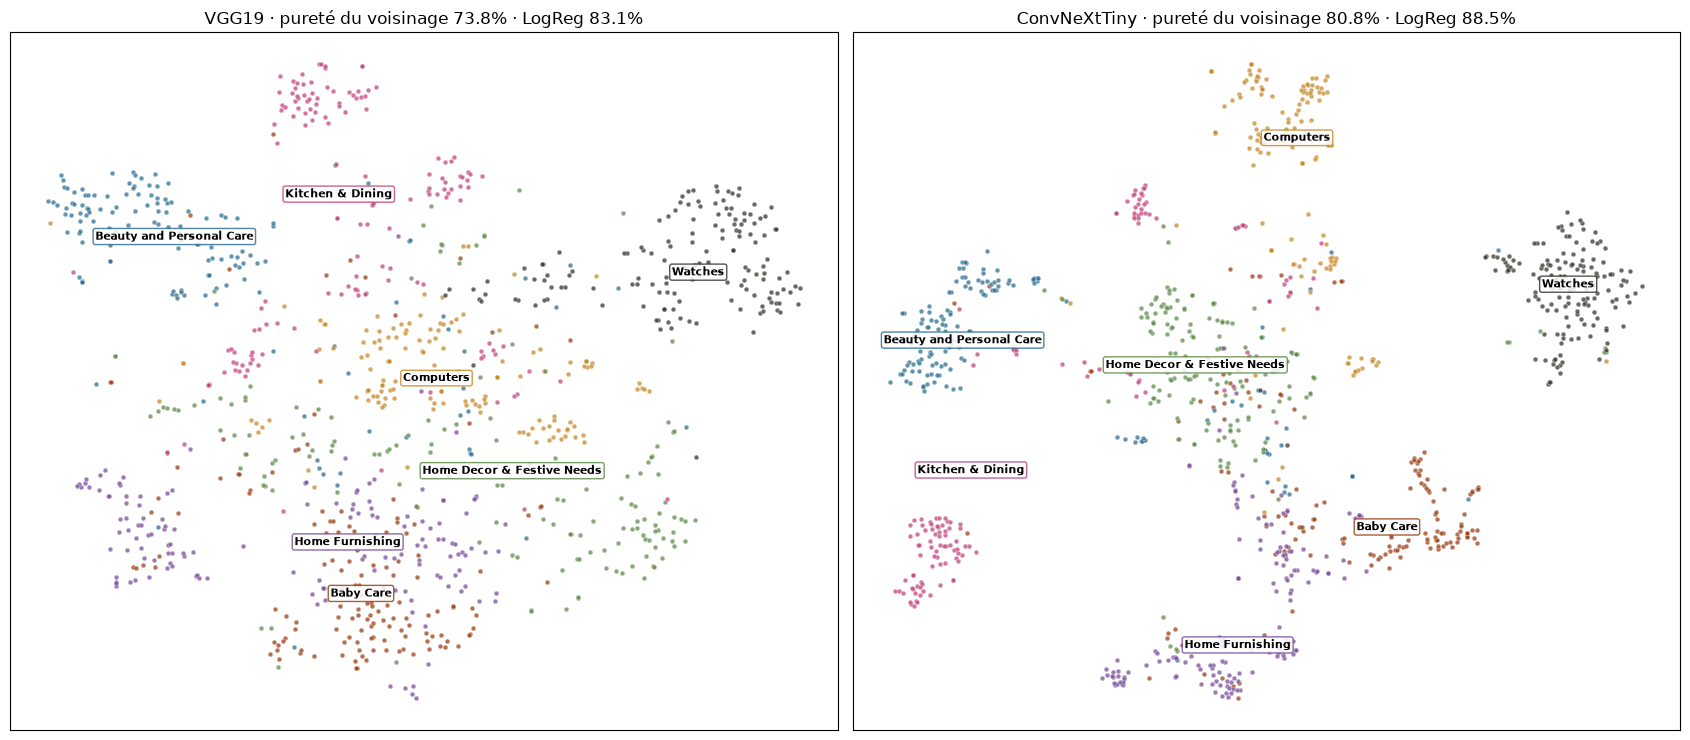

In [12]:
# t-SNE du meilleur modèle à côté de celui de VGG19
fig, axes = plt.subplots(1, 2, figsize=(17, 7.5))
for ax, nom in zip(axes, ["VGG19", MEILLEUR]):
    P = PROJ[nom]
    for cat in CATEGORIES:
        m = y == cat
        ax.scatter(P[m, 0], P[m, 1], s=12, alpha=0.75, color=couleurs[cat], edgecolors="white", linewidths=0.3, label=cat)
    for cat in CATEGORIES:
        cx, cy = np.median(P[y == cat], axis=0)
        ax.text(cx, cy, cat, fontsize=8, weight="bold", ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=couleurs[cat], alpha=0.85))
    ax.set_title(f"{nom} · pureté du voisinage {res.loc[nom, 'pureté t-SNE']:.1%} · LogReg {res.loc[nom, 'précision LogReg']:.1%}", fontsize=12)
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
sauver_figure(f"tsne_VGG19_vs_{MEILLEUR}.png", dpi=170, bbox_inches="tight")
plt.show()

## 8. Conclusion

*(rédigée après exécution, voir cellule suivante)*